In [66]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import argparse
import os
import numpy as np
import random
import yaml
import csv

from models.get_pretrained_model import get_pretrained_model
from datasets import get_dataset_class
from datasets.utils import TaggedMultipleDataset
from methods import get_method_class


In [67]:

def single_domain_test(datasets, tta_model, args):
    """
    Adaptation on each domain is independent, since the tta model is reset after each domain.
    """
    dataset_accs = []

    for i, dataset in enumerate(datasets):

        dataloader = DataLoader(dataset, batch_size=args.batch_size, shuffle=True, num_workers=args.num_workers,
                                pin_memory=True)

        num_correct, num_total = 0, 0
        for image, label in tqdm(dataloader):
            image, label = image.to(args.device), label.to(args.device)
            logits = tta_model(image)

            with torch.no_grad():
                pred = torch.argmax(logits, dim=1)
                num_correct += pred.eq(label).sum().item()
                num_total += label.size(0)

        dataset_accs.append(num_correct / num_total)
        tqdm.write(f"{datasets.environments[i]}: {dataset_accs[-1]}")

        tta_model.reset()

    domain_names = datasets.environments

    return domain_names, dataset_accs


def mixed_domain_test(datasets, tta_model, args):
    mix_dataset = TaggedMultipleDataset(datasets)

    dataset_num_corrects = torch.zeros(len(datasets), dtype=torch.int)
    dataset_num_samples = np.array([len(dataset) for dataset in datasets])

    dataloader = DataLoader(mix_dataset, batch_size=args.batch_size, shuffle=True, num_workers=args.num_workers,
                            pin_memory=True)

    for image, label, domain_idx, sample_idx in tqdm(dataloader):
        image, label = image.to(args.device), label.to(args.device)

        # image, label, mask = attack_model(image, label)
        # print(image.shape, label.shape)
        logits = tta_model(image)
        # logits = logits[mask]

        with torch.no_grad():
            pred = torch.argmax(logits, dim=1)
            is_correct = pred.eq(label).cpu().int()
            dataset_num_corrects.index_add_(0, domain_idx, is_correct)

    dataset_num_corrects = dataset_num_corrects.numpy()
    dataset_accs = dataset_num_corrects / dataset_num_samples

    domain_names = datasets.environments

    tta_model.reset()

    return domain_names, dataset_accs


In [68]:
def setup_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)

    torch.backends.cudnn.enabled = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True



In [69]:
num_of_threads = torch.get_num_threads()


# Experiment sweep runner

Reuses `single_domain_test` / `mixed_domain_test` from above (copied from `main.py`) so we can call the
TTA pipeline directly, in-process, instead of shelling out per-run like `shell/run_ramen.sh` does. This
lets us:

1. Sweep `dataset` x `model` x `tta_algo` x boolean flags (`use_tbn`, ...) and collect every run's
   per-domain accuracy into one tidy DataFrame.
2. Load the runs already saved under `../log/` (from `run_ramen.sh`) into the same format.
3. Plot per-domain accuracy to see exactly which corruption domains are dragging the average down,
   and compare flag on/off to see which flags actually move the needle.

Expects the same working directory as `main.py` (`src/`), so the existing imports above resolve.

In [70]:
import itertools
from types import SimpleNamespace

import pandas as pd
import matplotlib.pyplot as plt

DATA_ROOT = os.path.expanduser('~/data')
CONFIG_ROOT = '../cfg'
LOG_ROOT = '../log'
NUM_WORKERS = 0
NUM_THREADS = 4
SEED = 0

torch.set_num_threads(NUM_THREADS)
setup_seed(SEED)

print(f"cuda available: {torch.cuda.is_available()}")

cuda available: True


In [71]:
def load_tta_config(config_root, dataset, tta_algo):
    """Mirrors the yaml lookup in main.py's args_parser(): dataset-specific config first,
    falling back to cfg/default/<algo>.yaml (used by NoAdapt, which has no per-dataset cfg)."""
    filepaths = [
        os.path.join(config_root, dataset, tta_algo + '.yaml'),
        os.path.join(config_root, 'default', tta_algo + '.yaml'),
    ]
    for filepath in filepaths:
        if os.path.exists(filepath):
            with open(filepath, 'r') as f:
                return yaml.safe_load(f) or {}, filepath
    return {}, None


def build_args(dataset, model, tta_algo, tta_mode='mixed', batch_size=100,
               use_tbn=False, cuda=True, seed=SEED, config_overrides=None,
               data_root=DATA_ROOT, config_root=CONFIG_ROOT,
               num_workers=NUM_WORKERS, num_threads=NUM_THREADS):
    """Builds the same args object main.py's args_parser() would produce, without touching sys.argv,
    so every field methods/models read off `args` (args.device, args.config, args.max_batch_size, ...)
    is present."""
    config, config_path = load_tta_config(config_root, dataset, tta_algo)
    config = dict(config)
    if config_overrides:
        config.update(config_overrides)

    args = SimpleNamespace(
        dataset=dataset, data_root=data_root, tta_mode=tta_mode, model=model,
        use_tbn=use_tbn, tta_algo=tta_algo, batch_size=batch_size,
        num_workers=num_workers, seed=seed, cuda=cuda, num_threads=num_threads,
        config=config, config_path=config_path, save_to=None,
    )
    args.device = torch.device('cuda') if torch.cuda.is_available() and cuda else torch.device('cpu')
    args.max_batch_size = batch_size
    return args

In [72]:
def run_single_experiment(args, save_to=None, verbose=True):
    """Runs one (dataset, model, tta_algo, flags) config end-to-end, equivalent to main.py's main()
    but returning a record instead of only printing/saving."""
    setup_seed(args.seed)

    if verbose:
        print('-' * 80)
        print(f"dataset={args.dataset} model={args.model} tta_algo={args.tta_algo} "
             f"tta_mode={args.tta_mode} use_tbn={args.use_tbn} batch_size={args.batch_size}")

    model, preprocess = get_pretrained_model(args)
    datasets = get_dataset_class(args.dataset)(root=args.data_root, transform=preprocess)
    tta_method = get_method_class(args.tta_algo)(model, datasets, args)

    if args.tta_mode == 'single':
        domain_names, dataset_accs = single_domain_test(datasets, tta_method, args)
    elif args.tta_mode == 'mixed':
        domain_names, dataset_accs = mixed_domain_test(datasets, tta_method, args)
    else:
        raise ValueError(f'Unknown tta mode: {args.tta_mode}')

    avg_acc = float(np.mean(dataset_accs))

    if verbose:
        print('-' * 80)
        for env, acc in zip(domain_names, dataset_accs):
            print(f"{env}: {acc * 100:.2f}%")
        print(f"total: {avg_acc * 100:.2f}%")

    record = dict(
        dataset=args.dataset, model=args.model, tta_algo=args.tta_algo,
        tta_mode=args.tta_mode, use_tbn=args.use_tbn, batch_size=int(args.batch_size),
        seed=int(args.seed), avg_acc=avg_acc,
        domains=list(domain_names), accs=[float(a) for a in dataset_accs],
        config=dict(args.config),
    )

    if save_to is not None:
        os.makedirs(os.path.dirname(save_to), exist_ok=True)
        with open(save_to, "a", newline='') as f:
            writer = csv.writer(f)
            args_dict = {k: str(v) for k, v in vars(args).items() if isinstance(v, (int, str, float, bool))}
            writer.writerow([f"{k}={v}" for k, v in args_dict.items()])
            writer.writerow([f"{k}={v}" for k, v in args.config.items()])
            writer.writerow(list(domain_names) + ["Average"])
            accs_formatted = [f"{a * 100:.2f}" for a in dataset_accs]
            writer.writerow(accs_formatted + [f"{avg_acc * 100:.2f}"])
            writer.writerow([])

    # free GPU memory before the next run in the sweep
    del model, tta_method
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return record

In [73]:
def run_sweep(experiment_configs, save_dir=LOG_ROOT, save_csv=True):
    """experiment_configs: list of kwarg dicts for build_args(). Runs every config, tolerates
    individual failures (e.g. missing dataset on disk) without killing the whole sweep."""
    records = []
    for i, cfg in enumerate(experiment_configs):
        print(f"\n=== [{i + 1}/{len(experiment_configs)}] {cfg} ===")
        try:
            args = build_args(**cfg)
            save_to = None
            if save_csv:
                suffix = '_tbn1' if args.use_tbn else ''
                save_to = os.path.join(
                    save_dir, f"{args.dataset}_{args.tta_mode}",
                    f"{args.tta_algo}_{args.model}{suffix}.csv")
            records.append(run_single_experiment(args, save_to=save_to))
        except Exception as e:
            print(f"FAILED: {cfg} -> {e}")
            records.append(dict(cfg, error=str(e)))
    return records


def records_to_long_df(records):
    """Explodes each record's per-domain accuracies into one row per domain (tidy/long form)."""
    rows = []
    for r in records:
        if 'error' in r:
            continue
        for domain, acc in zip(r['domains'], r['accs']):
            rows.append(dict(
                dataset=r['dataset'], model=r['model'], tta_algo=r['tta_algo'],
                tta_mode=r['tta_mode'], use_tbn=bool(r['use_tbn']), batch_size=r['batch_size'],
                seed=r['seed'], domain=domain, accuracy=acc * 100, avg_acc=r['avg_acc'] * 100,
            ))
    return pd.DataFrame(rows)

## Define the sweep grid

`(dataset, model, batch_size)` triples mirror `shell/run_ramen.sh`. `TTA_ALGOS` toggles adaptation
on/off (`NoAdapt` = floor baseline, `Tent` = simple entropy-minimization TTA, `Ramen` = this repo's
method), and `USE_TBN_OPTIONS` toggles `--use_tbn`. Note: `use_tbn` only has an effect inside
`ModelForTTA` on `nn.BatchNorm2d` layers ([ModelForTTA.py:87-94](../src/models/ModelForTTA.py#L87-L94))
— the CLIP ViT backbones used here have no BatchNorm, only LayerNorm, so for `clip_vitbase*`/`clip_vitlarge*`
this flag is a no-op regardless of algo. It only matters if you add `clip_rn50`/`clip_rn101` to the grid.

In [74]:
# (dataset, model, batch_size) triples, same pairing as shell/run_ramen.sh
DATASET_MODEL_BATCH = [
    ('CIFAR10C',  'clip_vitbase32', 100),
    ('CIFAR100C', 'clip_vitbase16', 100),
    # ('ImageNetC5K', 'clip_vitlarge14', 50),
    # ('DomainNet',   'clip_vitbase32', 100),
]

TTA_ALGOS = ['NoAdapt', 'Tent', 'Ramen']
USE_TBN_OPTIONS = [False, True]
TTA_MODES = ['mixed']  # add 'single' too to compare shared-state vs per-domain-reset adaptation

experiment_configs = [
    dict(dataset=dataset, model=model, batch_size=batch_size,
        tta_algo=tta_algo, use_tbn=use_tbn, tta_mode=tta_mode)
    for (dataset, model, batch_size) in DATASET_MODEL_BATCH
    for tta_algo in TTA_ALGOS
    for use_tbn in (USE_TBN_OPTIONS if tta_algo != 'NoAdapt' else [False])
    for tta_mode in TTA_MODES
]

print(f"{len(experiment_configs)} configs queued:")
for c in experiment_configs:
    print(c)

10 configs queued:
{'dataset': 'CIFAR10C', 'model': 'clip_vitbase32', 'batch_size': 100, 'tta_algo': 'NoAdapt', 'use_tbn': False, 'tta_mode': 'mixed'}
{'dataset': 'CIFAR10C', 'model': 'clip_vitbase32', 'batch_size': 100, 'tta_algo': 'Tent', 'use_tbn': False, 'tta_mode': 'mixed'}
{'dataset': 'CIFAR10C', 'model': 'clip_vitbase32', 'batch_size': 100, 'tta_algo': 'Tent', 'use_tbn': True, 'tta_mode': 'mixed'}
{'dataset': 'CIFAR10C', 'model': 'clip_vitbase32', 'batch_size': 100, 'tta_algo': 'Ramen', 'use_tbn': False, 'tta_mode': 'mixed'}
{'dataset': 'CIFAR10C', 'model': 'clip_vitbase32', 'batch_size': 100, 'tta_algo': 'Ramen', 'use_tbn': True, 'tta_mode': 'mixed'}
{'dataset': 'CIFAR100C', 'model': 'clip_vitbase16', 'batch_size': 100, 'tta_algo': 'NoAdapt', 'use_tbn': False, 'tta_mode': 'mixed'}
{'dataset': 'CIFAR100C', 'model': 'clip_vitbase16', 'batch_size': 100, 'tta_algo': 'Tent', 'use_tbn': False, 'tta_mode': 'mixed'}
{'dataset': 'CIFAR100C', 'model': 'clip_vitbase16', 'batch_size': 100,

In [ ]:
RUN_EXPERIMENTS = True  # flip to True to actually execute the sweep (needs GPU + downloaded data at DATA_ROOT)

if RUN_EXPERIMENTS:
    sweep_records = run_sweep(experiment_configs)
    sweep_df = records_to_long_df(sweep_records)
else:
    sweep_records, sweep_df = [], pd.DataFrame()

sweep_df.head()

""


## Load existing results from `../log/`

`run_ramen.sh` has already produced real per-domain results (`../log/CIFAR10C_mixed/Ramen.csv`,
`../log/CIFAR100C_mixed/Ramen.csv`). Parse those in too, so the analysis below isn't limited to
whatever you re-run in this notebook.

In [76]:
def parse_log_csv(path):
    """Parses the block CSV format written by main.py / run_single_experiment: each run is 4 rows
    (args, config, domain header, values) followed by a blank line separator."""
    with open(path, newline='') as f:
        rows = [row for row in csv.reader(f)]

    records = []
    i = 0
    while i < len(rows):
        if not rows[i]:
            i += 1
            continue
        args_row, config_row, header_row, values_row = rows[i:i + 4]
        args_dict = dict(kv.split('=', 1) for kv in args_row)
        domains = header_row[:-1]
        accs = [float(v) / 100 for v in values_row[:-1]]
        avg_acc = float(values_row[-1]) / 100

        records.append(dict(
            dataset=args_dict.get('dataset'), model=args_dict.get('model'),
            tta_algo=args_dict.get('tta_algo'), tta_mode=args_dict.get('tta_mode'),
            use_tbn=args_dict.get('use_tbn') == 'True',
            batch_size=int(args_dict.get('batch_size', -1)),
            seed=int(args_dict.get('seed', -1)),
            domains=domains, accs=accs, avg_acc=avg_acc,
            source_file=path,
        ))
        i += 4

    return records


def load_all_logs(log_root=LOG_ROOT):
    all_records = []
    for dirpath, _, filenames in os.walk(log_root):
        for fname in sorted(filenames):
            if fname.endswith('.csv'):
                all_records.extend(parse_log_csv(os.path.join(dirpath, fname)))
    return all_records

log_records = load_all_logs()
log_df = records_to_long_df(log_records)
log_df.head()

,dataset,model,tta_algo,tta_mode,use_tbn,batch_size,seed,domain,accuracy,avg_acc
0,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,gaussian_noise,22.83,37.1
1,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,shot_noise,24.42,37.1
2,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,impulse_noise,29.58,37.1
3,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,defocus_blur,43.56,37.1
4,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,glass_blur,20.16,37.1


In [77]:
all_df = pd.concat([sweep_df, log_df], ignore_index=True) if not sweep_df.empty else log_df.copy()
all_df['flag'] = all_df['tta_algo'] + all_df['use_tbn'].map(lambda b: '+tbn' if b else '')
all_df.sort_values(['dataset', 'tta_algo', 'accuracy']).head(20)

,dataset,model,tta_algo,tta_mode,use_tbn,batch_size,seed,domain,accuracy,avg_acc,flag
4,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,glass_blur,20.16,37.10,NoAdapt
0,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,gaussian_noise,22.83,37.10,NoAdapt
1,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,shot_noise,24.42,37.10,NoAdapt
13,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,pixelate,26.29,37.10,NoAdapt
12,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,elastic_transform,29.21,37.10,NoAdapt
2,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,impulse_noise,29.58,37.10,NoAdapt
14,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,jpeg_compression,33.57,37.10,NoAdapt
11,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,contrast,35.27,37.10,NoAdapt
9,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,fog,41.77,37.10,NoAdapt
3,CIFAR100C,clip_vitbase16,NoAdapt,mixed,False,100,0,defocus_blur,43.56,37.10,NoAdapt


## Where is accuracy falling?

Per-domain bars, sorted ascending, with a dashed line at that run's own average. Bars below the
average are colored red — these are the corruption domains dragging the total down.

Weakest domains for CIFAR100C/NoAdapt (use_tbn=False):
           domain  accuracy
       glass_blur     20.16
   gaussian_noise     22.83
       shot_noise     24.42
         pixelate     26.29
elastic_transform     29.21


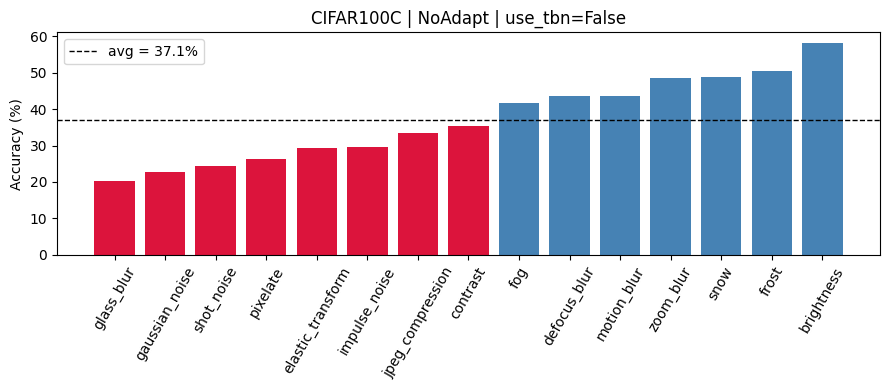

Weakest domains for CIFAR100C/Ramen (use_tbn=False):
           domain  accuracy
       glass_blur     29.34
   gaussian_noise     30.50
       shot_noise     32.77
elastic_transform     36.83
 jpeg_compression     39.15


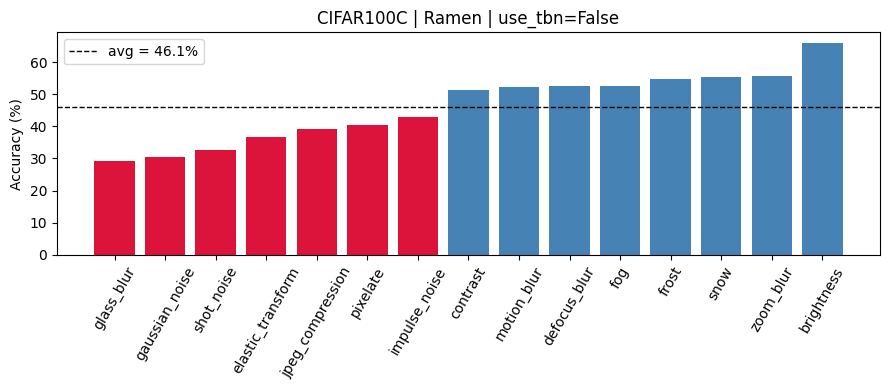

Weakest domains for CIFAR100C/Tent (use_tbn=False):
           domain  accuracy
       glass_blur     23.67
   gaussian_noise     24.87
       shot_noise     27.03
         pixelate     31.53
elastic_transform     31.81


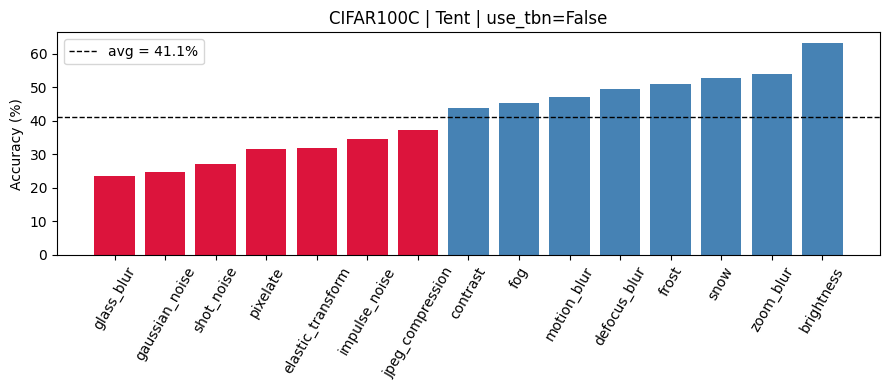

Weakest domains for CIFAR10C/NoAdapt (use_tbn=False):
        domain  accuracy
gaussian_noise     38.66
    shot_noise     42.59
 impulse_noise     42.75
    glass_blur     43.91
      pixelate     51.88


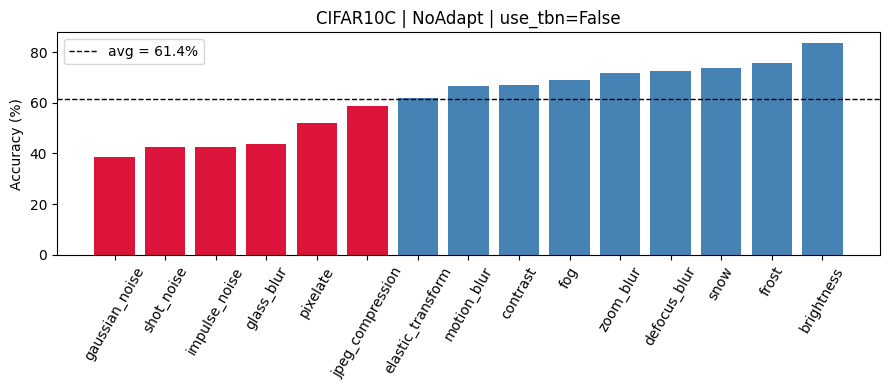

Weakest domains for CIFAR10C/Ramen (use_tbn=False):
        domain  accuracy
 impulse_noise     56.13
 impulse_noise     56.13
gaussian_noise     60.84
gaussian_noise     60.84
    shot_noise     63.35


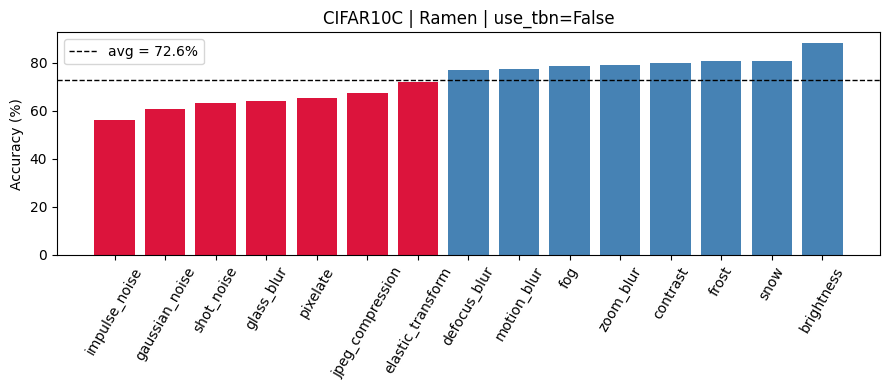

Weakest domains for CIFAR10C/Tent (use_tbn=False):
        domain  accuracy
gaussian_noise     38.60
    shot_noise     41.56
 impulse_noise     45.53
    glass_blur     56.22
      pixelate     60.55


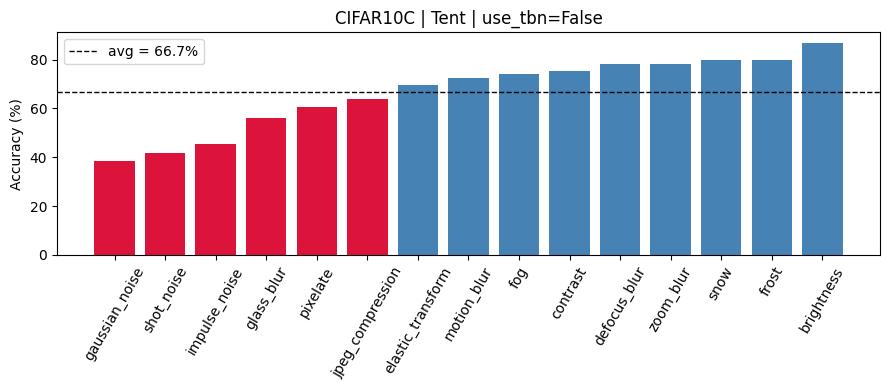

In [78]:
def plot_domain_accuracy(df, dataset, tta_algo=None, use_tbn=False, model=None, ax=None, top_n_worst=5):
    sub = df[df['dataset'] == dataset]
    if tta_algo is not None:
        sub = sub[sub['tta_algo'] == tta_algo]
    if use_tbn is not None:
        sub = sub[sub['use_tbn'] == use_tbn]
    if model is not None:
        sub = sub[sub['model'] == model]
    if sub.empty:
        print(f"No data for dataset={dataset} tta_algo={tta_algo} use_tbn={use_tbn} model={model}")
        return None

    sub = sub.sort_values('accuracy')
    avg = sub['accuracy'].mean()

    if ax is None:
        _, ax = plt.subplots(figsize=(9, 4))
    colors = ['crimson' if a < avg else 'steelblue' for a in sub['accuracy']]
    ax.bar(sub['domain'], sub['accuracy'], color=colors)
    ax.axhline(avg, color='black', linestyle='--', linewidth=1, label=f'avg = {avg:.1f}%')
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(f"{dataset} | {tta_algo or 'all algos'} | use_tbn={use_tbn}")
    ax.tick_params(axis='x', rotation=60)
    ax.legend()

    worst = sub.head(top_n_worst)
    print(f"Weakest domains for {dataset}/{tta_algo} (use_tbn={use_tbn}):")
    print(worst[['domain', 'accuracy']].to_string(index=False))
    return sub


for dataset in sorted(all_df['dataset'].unique()):
    for tta_algo in sorted(all_df[all_df['dataset'] == dataset]['tta_algo'].unique()):
        plot_domain_accuracy(all_df, dataset, tta_algo=tta_algo, use_tbn=False)
        plt.tight_layout()
        plt.show()

## Effect of each flag

Average accuracy per `(dataset, tta_algo, use_tbn)` — compares algorithms (adaptation on/off,
Tent vs Ramen) and the `use_tbn` toggle side by side. Requires `RUN_EXPERIMENTS = True` above for
the `NoAdapt`/`Tent`/`use_tbn=True` rows, since only `Ramen`/`use_tbn=False` is in the saved logs.

In [79]:
def flag_effect_table(df, index_cols=('dataset', 'tta_algo')):
    pivot = df.groupby(list(index_cols) + ['use_tbn'])['accuracy'].mean().unstack('use_tbn')
    pivot.columns = [f'use_tbn={c}' for c in pivot.columns]
    return pivot.round(2)

flag_effect_table(all_df)

use_tbn=False  use_tbn=True
dataset   tta_algo                             
CIFAR100C NoAdapt           37.10           NaN
          Ramen             46.12           NaN
          Tent              41.14         41.14
CIFAR10C  NoAdapt           61.36           NaN
          Ramen             72.63         72.63
          Tent              66.71         66.71

## Findings so far, and why

From the two runs already saved under `../log/` (Ramen, mixed mode, `use_tbn=False`):

- **CIFAR10C** (avg 72.63%): weakest domains are `impulse_noise` (56.13%), `gaussian_noise` (60.84%),
  `shot_noise` (63.35%) — 9-16 points below average. Blur/weather corruptions (`brightness` 88.14%,
  `zoom_blur` 78.84%, `snow` 80.79%) are all close to or above the mean.
- **CIFAR100C** (avg 46.12%): the same pattern, sharper — `glass_blur` (29.34%), `gaussian_noise`
  (30.50%), `shot_noise` (32.77%) are 14-17 points below average, while `brightness` (65.96%) and
  `zoom_blur` (55.65%) hold up fine.

**Hypothesis:** pixel-level noise corruptions (gaussian/shot/impulse) push CLIP's visual features
further out of the pretraining distribution than blur/weather corruptions do, so both the base
classifier's confidence *and* the entropy-minimization signal Ramen/Tent adapt on become unreliable —
confidently-wrong predictions reinforce themselves. This should be directly testable by comparing
`NoAdapt` vs `Tent` vs `Ramen` on the same weak domains once the sweep above is run — if adaptation
is actively hurting on noise domains, `NoAdapt`'s per-domain accuracy will beat `Ramen`/`Tent` there
even though it loses on average.

A few things specific to **this codebase** worth checking against the sweep results:

- `mixed_domain_test` only calls `tta_model.reset()` once, **after** the entire shuffled stream of
  all domains ([main.py:48-77](../src/main.py#L48-L77), reproduced in the cell above) — not per
  domain. So in `tta_mode=mixed`, Ramen's per-class cache and adapted LayerNorm affine params are
  shared continuously across every corruption domain in the mix. If noisy-domain samples generate
  confidently-wrong (low-entropy) predictions early, their gradients sit in the same per-class cache
  buckets used by easier domains and can pull adaptation in the wrong direction repo-wide, not just
  for that domain. Comparing `tta_mode='single'` (add it to `TTA_MODES` above) vs `'mixed'` isolates
  this effect directly.
- `PriorityCache.add` ([Ramen.py:29-64](../src/methods/Ramen.py#L29-L64)) evicts by `priorities`,
  but `priorities = torch.arange(counter, counter + B)` is just a monotonically increasing arrival
  counter — every new sample outranks every old one. So despite also tracking `entropies`, eviction
  is effectively a per-class FIFO (always keep the most recent `max_capacity` samples), not
  confidence-based. Under noise corruptions, that means the cache can fill up with recent
  confidently-wrong samples that evict earlier, possibly-correct ones.
- `--use_tbn` only changes behavior inside `ModelForTTA` on `nn.BatchNorm2d` modules
  ([ModelForTTA.py:87-94](../src/models/ModelForTTA.py#L87-L94)). All CLIP ViT backbones have no
  BatchNorm2d — only LayerNorm — so this flag is a no-op for every model in the current sweep grid;
  it will only show a difference in the table above if you add `clip_rn50`/`clip_rn101`.
- `beta` (in `cfg/<dataset>/Ramen.yaml`) controls how much cache retrieval down-weights distant
  neighbors (`exp(-beta * dist)` in [Ramen.py:148](../src/methods/Ramen.py#L148)). It's `5.0` for
  CIFAR10C/CIFAR100C/DomainNet but `0.0` for ImageNetC5K (distance weighting fully disabled there).
  That's an easy additional on/off ablation: pass `config_overrides=dict(beta=0.0)` to `build_args()`
  for CIFAR10C/100C and compare against the default `beta=5.0` runs.

## Ablation 1: `tta_mode='single'` vs `'mixed'` — is cross-domain cache sharing actually hurting?

`mixed_domain_test` shares one persistent cache + adapted LayerNorm state across the *entire*
shuffled stream ([main.py:48-77](../src/main.py#L48-L77)); `single_domain_test` resets after every
domain. If confidently-wrong pseudo-labels from noise domains are polluting the shared per-class
cache and dragging down *other* domains too, `Ramen(single)` should beat `Ramen(mixed)` specifically
on domains near the noise domains in the stream — not just on the noise domains themselves (those
may still be near-irrecoverable in single mode, since the frozen-backbone t-SNE plots show no class
structure to adapt with regardless of cache sharing).

Only `Ramen` is run here (`NoAdapt` is stateless — mode doesn't affect it; `Tent` is optional, add it
to `ABLATION_ALGOS` below if useful). Results are saved under `../log/ablations/` so they don't get
silently merged into `all_df`/`flag_effect_table` above.

In [ ]:
ABLATION_LOG_ROOT = os.path.join(LOG_ROOT, 'ablations')
ABLATION_ALGOS = ['Ramen']  # add 'Tent' too if you want the comparison for it as well

mode_ablation_configs = [
    dict(dataset=dataset, model=model, batch_size=batch_size,
        tta_algo=tta_algo, use_tbn=False, tta_mode=tta_mode)
    for (dataset, model, batch_size) in DATASET_MODEL_BATCH
    for tta_algo in ABLATION_ALGOS
    for tta_mode in ['single', 'mixed']
]

print(f"{len(mode_ablation_configs)} configs queued:")
for c in mode_ablation_configs:
    print(c)

RUN_MODE_ABLATION = True  # flip to True to actually execute (needs GPU + downloaded data)

if RUN_MODE_ABLATION:
    mode_ablation_records = run_sweep(mode_ablation_configs, save_dir=ABLATION_LOG_ROOT)
    mode_ablation_df = records_to_long_df(mode_ablation_records)
else:
    mode_ablation_records, mode_ablation_df = [], pd.DataFrame()

mode_ablation_df.head()

In [ ]:
def mode_comparison_table(df):
    pivot = df.pivot_table(index=['dataset', 'domain'], columns='tta_mode', values='accuracy')
    sort_cols = ['dataset']
    ascending = [True]
    if 'single' in pivot.columns and 'mixed' in pivot.columns:
        pivot['single_minus_mixed'] = pivot['single'] - pivot['mixed']
        sort_cols.append('single_minus_mixed')
        ascending.append(False)
    return pivot.round(2).sort_values(sort_cols, ascending=ascending)

NOISE_DOMAINS = {'gaussian_noise', 'shot_noise', 'impulse_noise'}

cmp_df = mode_comparison_table(mode_ablation_df)
print("Per-domain accuracy, single vs mixed (positive single_minus_mixed => mixed's shared cache is hurting this domain):")
print(cmp_df.to_string())

if 'single_minus_mixed' in cmp_df.columns:
    print("\nSummary — mean single_minus_mixed, noise domains vs the rest:")
    cmp_reset = cmp_df.reset_index()
    cmp_reset['is_noise'] = cmp_reset['domain'].isin(NOISE_DOMAINS)
    print(cmp_reset.groupby(['dataset', 'is_noise'])['single_minus_mixed'].agg(['mean', 'count']).round(2))
else:
    print("\nMissing 'single' or 'mixed' rows — check for FAILED configs above.")

## Ablation 2: `beta` (domain-consistency distance weighting) on vs off

`beta` scales the distance term in the retrieval weight, `exp(-beta * dist)` in
[Ramen.py:148](../src/methods/Ramen.py#L148) — it's `5.0` in `cfg/CIFAR10C/Ramen.yaml` and
`cfg/CIFAR100C/Ramen.yaml`, but `0.0` in the paper's own ImageNetC5K config (distance weighting
fully disabled). Setting `beta=0.0` here keeps prediction-balance (class-split queues) but removes
domain-consistency weighting from aggregation, isolating how much of Ramen's gain is coming from
each criterion — no code change needed, `config_overrides` already threads through `build_args`.

In [ ]:
beta_ablation_configs = [
    dict(dataset=dataset, model=model, batch_size=batch_size,
        tta_algo='Ramen', use_tbn=False, tta_mode='mixed', config_overrides=dict(beta=beta))
    for (dataset, model, batch_size) in DATASET_MODEL_BATCH
    for beta in [5.0, 0.0]  # 5.0 = default (already in cfg/*/Ramen.yaml), 0.0 = distance weighting off
]

print(f"{len(beta_ablation_configs)} configs queued:")
for c in beta_ablation_configs:
    print(c)

RUN_BETA_ABLATION = True  # flip to True to actually execute (needs GPU + downloaded data)

if RUN_BETA_ABLATION:
    beta_ablation_records = []
    for cfg in beta_ablation_configs:
        args = build_args(**cfg)
        beta_val = args.config['beta']
        save_to = os.path.join(ABLATION_LOG_ROOT, f"{args.dataset}_{args.tta_mode}_beta{beta_val}",
                               f"{args.tta_algo}_{args.model}.csv")
        try:
            record = run_single_experiment(args, save_to=save_to)
            record['beta'] = beta_val
        except Exception as e:
            print(f"FAILED: {cfg} -> {e}")
            record = dict(cfg, beta=beta_val, error=str(e))
        beta_ablation_records.append(record)

    beta_ablation_df = records_to_long_df(beta_ablation_records)
    beta_ablation_df['beta'] = [r['beta'] for r in beta_ablation_records if 'error' not in r
                                for _ in r['domains']]
else:
    beta_ablation_records, beta_ablation_df = [], pd.DataFrame()

beta_ablation_df.head()

In [ ]:
def beta_comparison_table(df):
    pivot = df.pivot_table(index=['dataset', 'domain'], columns='beta', values='accuracy')
    sort_cols = ['dataset']
    ascending = [True]
    if 5.0 in pivot.columns and 0.0 in pivot.columns:
        pivot['beta5_minus_beta0'] = pivot[5.0] - pivot[0.0]
        sort_cols.append('beta5_minus_beta0')
        ascending.append(False)
    return pivot.round(2).sort_values(sort_cols, ascending=ascending)

beta_cmp_df = beta_comparison_table(beta_ablation_df)
print("Per-domain accuracy, beta=5.0 (default) vs beta=0.0 (distance weighting off):")
print(beta_cmp_df.to_string())

print("\nOverall avg accuracy by beta:")
print(beta_ablation_df.groupby(['dataset', 'beta'])['accuracy'].mean().round(2))

if 'beta5_minus_beta0' in beta_cmp_df.columns:
    print("\nSummary — mean beta5_minus_beta0, noise domains vs the rest:")
    beta_cmp_reset = beta_cmp_df.reset_index()
    beta_cmp_reset['is_noise'] = beta_cmp_reset['domain'].isin(NOISE_DOMAINS)
    print(beta_cmp_reset.groupby(['dataset', 'is_noise'])['beta5_minus_beta0'].agg(['mean', 'count']).round(2))
else:
    print("\nMissing beta=5.0 or beta=0.0 rows — check for FAILED configs above.")

## Visual diagnostics: misclassified images & confusion matrices

Everything above only looks at aggregate accuracy. To see *what* is going wrong, we need per-sample
predictions, not just per-domain totals — `single_domain_test`/`mixed_domain_test` above only return
counts. `collect_predictions()` below runs the same adaptation loop but keeps every sample's true
label, predicted label, and its `(domain_idx, sample_idx)` so we can look the original image back up
afterward and build confusion matrices.

In [80]:
from PIL import Image
from torchvision.datasets.folder import default_loader


def collect_predictions(datasets, tta_model, args):
    """Same adaptation loop as single_domain_test / mixed_domain_test above, but records every
    sample's (domain_idx, sample_idx, label, pred) instead of only aggregate counts. Uses
    shuffle=False in single mode (batches are contiguous, so sample_idx == position within the
    domain's dataset); mixed mode already gets sample_idx for free from TaggedMultipleDataset."""
    records = []

    if args.tta_mode == 'single':
        for domain_idx, dataset in enumerate(datasets):
            dataloader = DataLoader(dataset, batch_size=args.batch_size, shuffle=False,
                                    num_workers=args.num_workers, pin_memory=True)
            offset = 0
            for image, label in tqdm(dataloader, desc=datasets.environments[domain_idx]):
                image, label = image.to(args.device), label.to(args.device)
                logits = tta_model(image)
                with torch.no_grad():
                    pred = torch.argmax(logits, dim=1)
                for b in range(label.size(0)):
                    records.append(dict(domain_idx=domain_idx, sample_idx=offset + b,
                                        label=int(label[b]), pred=int(pred[b])))
                offset += label.size(0)
            tta_model.reset()

    elif args.tta_mode == 'mixed':
        mix_dataset = TaggedMultipleDataset(datasets)
        dataloader = DataLoader(mix_dataset, batch_size=args.batch_size, shuffle=True,
                                num_workers=args.num_workers, pin_memory=True)
        for image, label, domain_idx, sample_idx in tqdm(dataloader):
            image, label = image.to(args.device), label.to(args.device)
            logits = tta_model(image)
            with torch.no_grad():
                pred = torch.argmax(logits, dim=1)
            for b in range(label.size(0)):
                records.append(dict(domain_idx=int(domain_idx[b]), sample_idx=int(sample_idx[b]),
                                    label=int(label[b]), pred=int(pred[b])))
        tta_model.reset()

    else:
        raise ValueError(f'Unknown tta mode: {args.tta_mode}')

    return pd.DataFrame(records)


def run_for_confusion(cfg, verbose=True):
    """Builds args + model + method for one sweep config (same kwargs as run_sweep's configs),
    runs one full pass, and returns (datasets, pred_df) — the raw datasets object (needed to look
    up images/class names/environments) and a per-sample prediction DataFrame."""
    args = build_args(**cfg)
    setup_seed(args.seed)

    model, preprocess = get_pretrained_model(args)
    datasets = get_dataset_class(args.dataset)(root=args.data_root, transform=preprocess)
    tta_method = get_method_class(args.tta_algo)(model, datasets, args)

    pred_df = collect_predictions(datasets, tta_method, args)
    pred_df['dataset'] = args.dataset
    pred_df['tta_algo'] = args.tta_algo
    pred_df['domain'] = pred_df['domain_idx'].map(lambda i: datasets.environments[i])
    pred_df['class_name'] = pred_df['label'].map(lambda i: datasets.classes[i])
    pred_df['pred_class_name'] = pred_df['pred'].map(lambda i: datasets.classes[i])
    pred_df['correct'] = pred_df['label'] == pred_df['pred']

    if verbose:
        acc = pred_df['correct'].mean()
        print(f"{args.dataset}/{args.tta_algo}: overall acc = {acc * 100:.2f}% over {len(pred_df)} samples")

    del model, tta_method
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return datasets, pred_df


def get_raw_image(datasets, domain_idx, sample_idx):
    """Fetches the *untransformed* image for display, bypassing CLIP preprocessing (which
    resizes/normalizes into something imshow can't render meaningfully)."""
    dataset = datasets.datasets[domain_idx]
    if hasattr(dataset, 'X'):  # corruption datasets, numpy-backed (CIFAR10C/100C/ImageNetC*)
        return Image.fromarray(dataset.X[sample_idx], mode='RGB')
    if hasattr(dataset, 'samples'):  # domainbed datasets, torchvision ImageFolder-backed
        path, _ = dataset.samples[sample_idx]
        return default_loader(path)
    raise TypeError(f"Don't know how to fetch a raw image from {type(dataset)}")

In [81]:
def compute_confusion_matrix(pred_df, num_classes):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    np.add.at(cm, (pred_df['label'].values, pred_df['pred'].values), 1)
    return cm


def plot_confusion_matrix(cm, class_names, title='', normalize=True, ax=None, annotate_max=20):
    """Row-normalized by default (each row = one true class, sums to 1) so classes with different
    sample counts are still comparable. Cell values are only annotated when there are few enough
    classes to read (CIFAR10C); CIFAR100C/ImageNetC5K just render as a heatmap."""
    if normalize:
        with np.errstate(divide='ignore', invalid='ignore'):
            cm_display = cm / cm.sum(axis=1, keepdims=True)
            cm_display = np.nan_to_num(cm_display)
    else:
        cm_display = cm.astype(float)

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    im = ax.imshow(cm_display, cmap='Blues', vmin=0, vmax=cm_display.max())
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    n = len(class_names)
    if n <= annotate_max:
        ax.set_xticks(range(n))
        ax.set_xticklabels(class_names, rotation=90, fontsize=7)
        ax.set_yticks(range(n))
        ax.set_yticklabels(class_names, fontsize=7)
        for i in range(n):
            for j in range(n):
                if cm[i, j] > 0:
                    ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=6,
                            color='white' if cm_display[i, j] > 0.5 else 'black')
    else:
        ax.set_xticks([])
        ax.set_yticks([])

    return ax


def top_confusions(cm, class_names, k=10):
    """Biggest off-diagonal (true, pred) mass — the specific class pairs most responsible for errors."""
    cm = cm.copy()
    np.fill_diagonal(cm, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-cm, axis=None), cm.shape))[0][:k]
    rows = [dict(true=class_names[i], pred=class_names[j], count=int(cm[i, j]))
            for i, j in idx if cm[i, j] > 0]
    return pd.DataFrame(rows)


def weakest_domain(pred_df):
    return pred_df.groupby('domain')['correct'].mean().idxmin()

In [82]:
def show_misclassified(datasets, pred_df, domain=None, n=12, ncols=4, seed=SEED):
    """Grid of randomly-sampled misclassified images with true vs. predicted class in the title."""
    wrong = pred_df[~pred_df['correct']]
    if domain is not None:
        wrong = wrong[wrong['domain'] == domain]
    if wrong.empty:
        print(f"No misclassified samples found (domain={domain}).")
        return

    sample = wrong.sample(n=min(n, len(wrong)), random_state=seed)
    nrows = int(np.ceil(len(sample) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).flatten()

    for ax, (_, row) in zip(axes, sample.iterrows()):
        img = get_raw_image(datasets, row['domain_idx'], row['sample_idx'])
        ax.imshow(img)
        ax.set_title(f"{row['domain']}\ntrue: {row['class_name']}\npred: {row['pred_class_name']}",
                    fontsize=8, color='crimson')
        ax.axis('off')
    for ax in axes[len(sample):]:
        ax.axis('off')

    fig.suptitle(f"Misclassified examples" + (f" — {domain}" if domain else ""), y=1.02)
    plt.tight_layout()
    plt.show()


def show_correct_vs_wrong(datasets, pred_df, domain, n_each=6, seed=SEED):
    """Side-by-side: correctly vs incorrectly classified images from the same domain, so you can
    visually compare what the corruption actually looks like on images the model still got right."""
    sub = pred_df[pred_df['domain'] == domain]
    correct = sub[sub['correct']].sample(n=min(n_each, (sub['correct']).sum()), random_state=seed)
    wrong = sub[~sub['correct']].sample(n=min(n_each, (~sub['correct']).sum()), random_state=seed)

    fig, axes = plt.subplots(2, n_each, figsize=(2.5 * n_each, 5.5))
    for ax, (_, row) in zip(axes[0], correct.iterrows()):
        ax.imshow(get_raw_image(datasets, row['domain_idx'], row['sample_idx']))
        ax.set_title(row['class_name'], fontsize=8, color='steelblue')
        ax.axis('off')
    for ax, (_, row) in zip(axes[1], wrong.iterrows()):
        ax.imshow(get_raw_image(datasets, row['domain_idx'], row['sample_idx']))
        ax.set_title(f"true:{row['class_name']}\npred:{row['pred_class_name']}", fontsize=8, color='crimson')
        ax.axis('off')
    for ax in axes[0][len(correct):]:
        ax.axis('off')
    for ax in axes[1][len(wrong):]:
        ax.axis('off')

    axes[0][0].set_ylabel('correct', fontsize=10)
    axes[1][0].set_ylabel('wrong', fontsize=10)
    fig.suptitle(f"{domain}: correct vs. wrong", y=1.02)
    plt.tight_layout()
    plt.show()

### Run diagnostics for a config

Runs a full forward pass per config (needs GPU + downloaded data, same as `RUN_EXPERIMENTS` above) and
keeps every sample's prediction in memory — heavier than the aggregate sweep, so keep `diagnostics_configs`
short. Add/remove entries (any `dict` accepted by `build_args`) to inspect other datasets/algos/flags.

In [ ]:
RUN_DIAGNOSTICS = True  # flip to True to run models and collect per-sample predictions

diagnostics_configs = [
    dict(dataset='CIFAR10C', model='clip_vitbase32', batch_size=100, tta_algo='Ramen', use_tbn=False, tta_mode='mixed'),
    dict(dataset='CIFAR100C', model='clip_vitbase16', batch_size=100, tta_algo='Ramen', use_tbn=False, tta_mode='mixed'),
]

diagnostics = {}  # (dataset, tta_algo) -> (datasets_obj, pred_df)

if RUN_DIAGNOSTICS:
    for cfg in diagnostics_configs:
        datasets_obj, pred_df = run_for_confusion(cfg)
        diagnostics[(cfg['dataset'], cfg['tta_algo'])] = (datasets_obj, pred_df)
else:
    print("RUN_DIAGNOSTICS is False — set it to True above to populate `diagnostics`.")

RUN_DIAGNOSTICS is False — set it to True above to populate `diagnostics`.


In [84]:
if not diagnostics:
    print("`diagnostics` is empty — run the cell above with RUN_DIAGNOSTICS = True first.")

for (dataset, tta_algo), (datasets_obj, pred_df) in diagnostics.items():
    print('=' * 80)
    print(f"{dataset} / {tta_algo}")

    cm = compute_confusion_matrix(pred_df, datasets_obj.num_classes)
    plot_confusion_matrix(cm, datasets_obj.classes, title=f"{dataset} / {tta_algo} (row-normalized)")
    plt.show()

    print("Top confused class pairs:")
    print(top_confusions(cm, datasets_obj.classes, k=10).to_string(index=False))

    worst_domain = weakest_domain(pred_df)
    domain_acc = pred_df[pred_df['domain'] == worst_domain]['correct'].mean()
    print(f"\nWeakest domain in this run: {worst_domain} ({domain_acc * 100:.2f}% acc)")

    show_misclassified(datasets_obj, pred_df, domain=worst_domain, n=12)
    show_correct_vs_wrong(datasets_obj, pred_df, domain=worst_domain, n_each=6)

`diagnostics` is empty — run the cell above with RUN_DIAGNOSTICS = True first.


## t-SNE of visual feature embeddings

Ramen/Tent classify by cosine similarity between a sample's CLIP visual embedding and each class's
text-embedding prototype ([Ramen.py:246-247](../src/methods/Ramen.py) /
[ModelForTTA.py](../src/models/ModelForTTA.py) `classify()`). Accuracy falls whenever a corruption
pushes a sample's embedding closer to the wrong class's prototype than its own. t-SNE lets us see
that geometry directly: project each sample's embedding to 2D and color it two ways —

- **by class** — if classes still form separated clusters, the corruption hasn't destroyed
  class-discriminative structure, it's shifted it (something adaptation could plausibly fix).
- **by corruption domain** — if points cluster by *domain* instead of by class, the corruption's
  own signature dominates the embedding more than the object identity does, which is a much harder
  problem for any TTA method built on this feature space (adapting normalization stats won't
  recover class structure that isn't there in the frozen backbone's output).

This extracts features from the **frozen pretrained** CLIP visual encoder (no TTA applied) — i.e. the
starting point every method here is trying to correct. Requires `scikit-learn` (`pip install
scikit-learn` if the import below fails).

In [85]:
import torch.nn.functional as F

try:
    from sklearn.manifold import TSNE
except ImportError as e:
    raise ImportError(
        "t-SNE needs scikit-learn, which isn't installed in this environment. "
        "Run `pip install scikit-learn` (in the same env as this kernel) and re-run this cell."
    ) from e


class PretrainedFeaturizer:
    """Wraps the raw, un-adapted CLIP visual encoder with the same .featurize(x) -> normalized
    embedding interface CLIPModelForTTA / CLIPModelForBySampleTTA use, so extract_features() below
    works the same regardless of which method's featurizer you pass in."""

    def __init__(self, model):
        self.model = model.visual
        # NOT next(self.model.parameters()).dtype: VisionTransformer registers
        # class_embedding/positional_embedding (float32, never cast by CLIP's convert_weights)
        # before its conv1 submodule in parameter-iteration order, so that would silently pick
        # up float32 even though the conv/linear layers are half. Match ModelForBySampleTTA.py /
        # ModelForTTA.py, which read the dtype off conv1.weight directly for this reason.
        self.dtype = self.model.conv1.weight.dtype

    def featurize(self, x):
        return F.normalize(self.model(x.type(self.dtype)), dim=1)


@torch.no_grad()
def extract_features(featurizer, datasets, args, max_samples_per_domain=150, seed=SEED):
    """Extracts L2-normalized visual embeddings for a random subset of samples per domain.
    Returns (feats: N x D ndarray, meta: DataFrame with domain_idx/sample_idx/label per row, same
    row order as feats)."""
    rng = np.random.RandomState(seed)
    feat_chunks, meta_rows = [], []

    for domain_idx, dataset in enumerate(datasets):
        n = len(dataset)
        idxs = rng.choice(n, size=min(max_samples_per_domain, n), replace=False)
        subset = torch.utils.data.Subset(dataset, idxs)
        dataloader = DataLoader(subset, batch_size=args.batch_size, shuffle=False,
                                num_workers=args.num_workers, pin_memory=True)

        ptr = 0
        for image, label in tqdm(dataloader, desc=f"features: {datasets.environments[domain_idx]}"):
            image = image.to(args.device)
            feat = featurizer.featurize(image).float().cpu().numpy()
            B = feat.shape[0]
            feat_chunks.append(feat)
            for b in range(B):
                meta_rows.append(dict(domain_idx=domain_idx, sample_idx=int(idxs[ptr + b]),
                                      label=int(label[b])))
            ptr += B

    feats = np.concatenate(feat_chunks, axis=0)
    meta = pd.DataFrame(meta_rows)
    return feats, meta


def run_tsne(feats, seed=SEED, **tsne_kwargs):
    tsne = TSNE(n_components=2, init='pca', random_state=seed, **tsne_kwargs)
    return tsne.fit_transform(feats)

In [86]:
def plot_tsne_by_class(xy, meta, classes, title='', ax=None, max_classes_labeled=20):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    cmap = plt.get_cmap('tab20', len(classes))
    ax.scatter(xy[:, 0], xy[:, 1], c=meta['label'].values, cmap=cmap, s=8, alpha=0.7)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    if len(classes) <= max_classes_labeled:
        handles = [plt.Line2D([0], [0], marker='o', linestyle='', color=cmap(i), label=c)
                  for i, c in enumerate(classes)]
        ax.legend(handles=handles, fontsize=6, bbox_to_anchor=(1.02, 1), loc='upper left')
    return ax


def plot_tsne_by_domain(xy, meta, environments, title='', ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    cmap = plt.get_cmap('tab20', len(environments))
    domain_idxs = meta['domain_idx'].values
    for d, env in enumerate(environments):
        mask = domain_idxs == d
        ax.scatter(xy[mask, 0], xy[mask, 1], s=8, alpha=0.6, color=cmap(d), label=env)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(fontsize=6, bbox_to_anchor=(1.02, 1), loc='upper left')
    return ax

In [87]:
RUN_TSNE = True  # flip to True to extract features + fit t-SNE (needs GPU + data + scikit-learn)

tsne_configs = [
    dict(dataset='CIFAR10C', model='clip_vitbase32', batch_size=100),
    dict(dataset='CIFAR100C', model='clip_vitbase16', batch_size=100),
]

tsne_results = {}  # dataset -> (xy, meta, datasets_obj)

if RUN_TSNE:
    for cfg in tsne_configs:
        args = build_args(tta_algo='NoAdapt', **cfg)  # tta_algo unused here, just needed for build_args
        setup_seed(args.seed)

        base_model, preprocess = get_pretrained_model(args)
        datasets_obj = get_dataset_class(args.dataset)(root=args.data_root, transform=preprocess)
        featurizer = PretrainedFeaturizer(base_model)

        feats, meta = extract_features(featurizer, datasets_obj, args)
        print(f"{args.dataset}: t-SNE on {feats.shape[0]} points ({feats.shape[1]}-d)...")
        xy = run_tsne(feats)
        tsne_results[args.dataset] = (xy, meta, datasets_obj)

        del base_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
else:
    print("RUN_TSNE is False — set it to True above to populate `tsne_results`.")

features: jpeg_compression: 100%|██████████| 2/2 [00:00<00:00,  9.32it/s]


CIFAR10C: t-SNE on 2250 points (512-d)...


features: jpeg_compression: 100%|██████████| 2/2 [00:00<00:00,  6.55it/s]


CIFAR100C: t-SNE on 2250 points (512-d)...


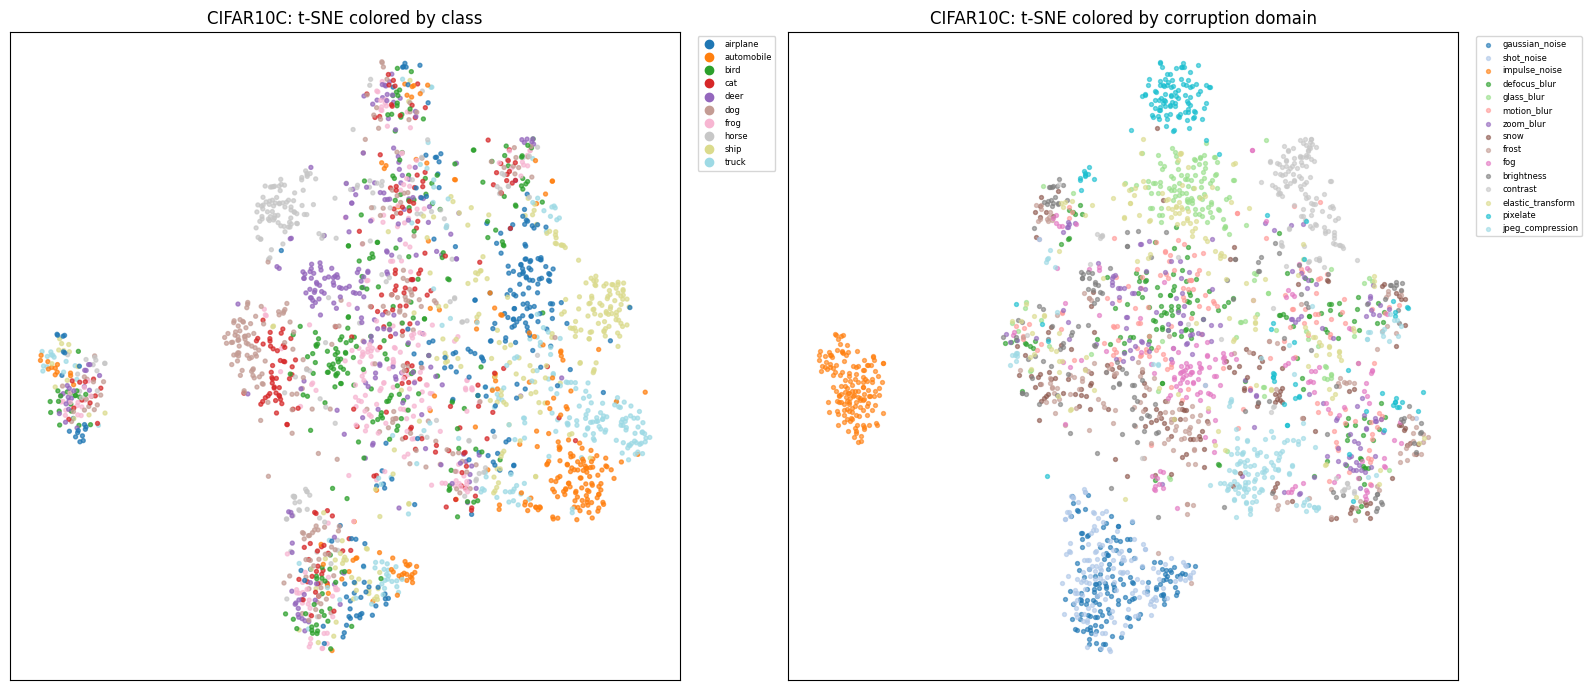

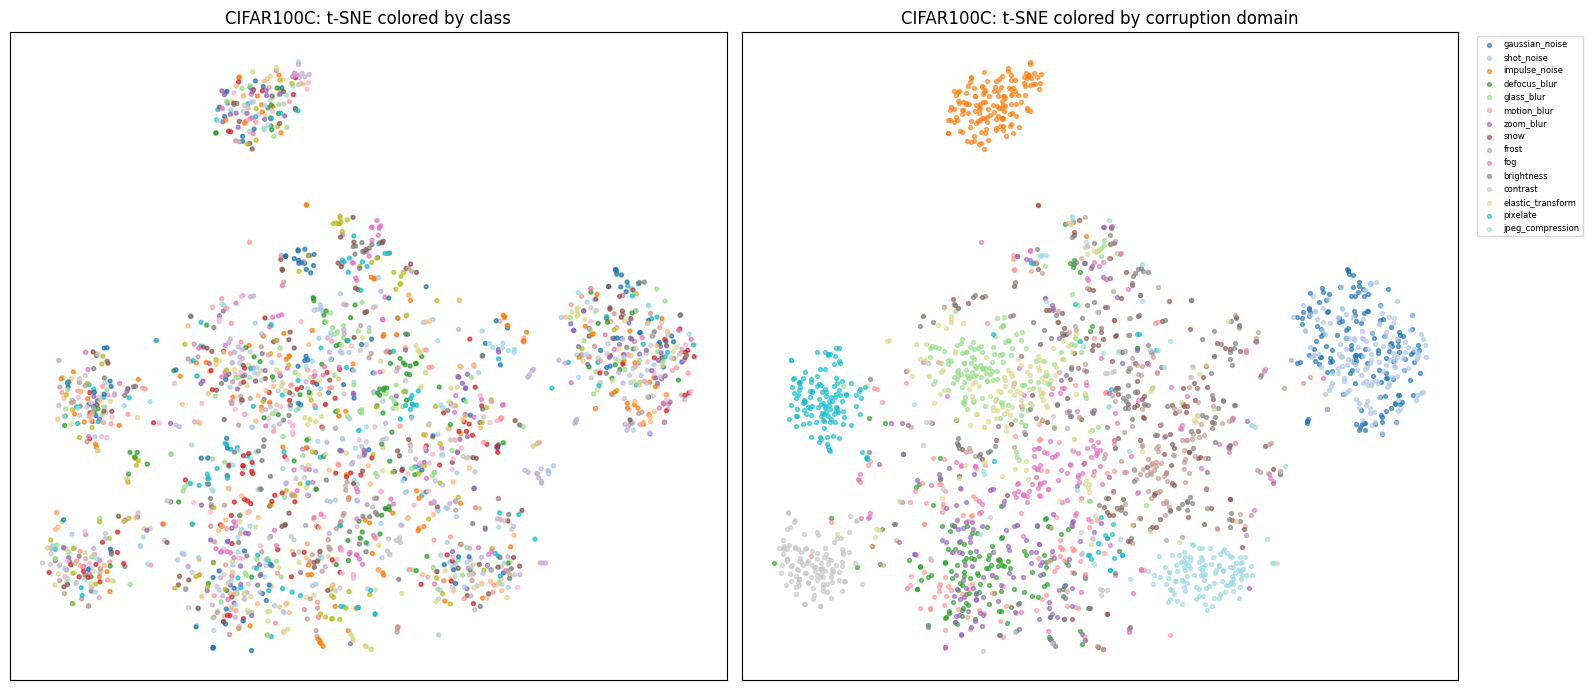

In [88]:
if not tsne_results:
    print("`tsne_results` is empty — run the cell above with RUN_TSNE = True first.")

for dataset, (xy, meta, datasets_obj) in tsne_results.items():
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    plot_tsne_by_class(xy, meta, datasets_obj.classes,
                       title=f"{dataset}: t-SNE colored by class", ax=axes[0])
    plot_tsne_by_domain(xy, meta, datasets_obj.environments,
                        title=f"{dataset}: t-SNE colored by corruption domain", ax=axes[1])
    plt.tight_layout()
    plt.show()